# Part 1: Pocket PLA

Run top to bottom. `FAST=0` runs at full scale (see README).

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt
import mlcore as mc

FAST = mc.fast_mode()  # R2: FAST=0 for full scale
rng = np.random.default_rng(mc.SEED)  # R2 seed; experiments use mc.rng_for(tag)
print(f"FAST={FAST}")

FAST=True


## Part 0 toolkit tests

In [2]:
%run test_mlcore.py

PASS test_rng_for
PASS test_mean_se
PASS test_hoeffding
PASS test_savefig_name
PASS test_legendre_vs_legval
PASS test_poly_counts
PASS test_legendre_tensor
PASS test_standardize_train_only
PASS test_minmax
PASS test_kfold
PASS test_stratified_split
PASS test_confusion_f1_hand
PASS test_auc_known
PASS test_regression_metrics
PASS test_gradient_check_quadratic
PASS test_grad_linreg
PASS test_grad_logistic
PASS test_logistic_stable
PASS test_solvers_agree
PASS test_soft_threshold
PASS test_ein_01
PASS test_ridge_vs_direct
PASS test_ridge_deff_limits
PASS test_ridge_hat_diag
PASS test_ridge_rank_deficient
PASS test_ridge_requires_bias
PASS test_pla_separable
PASS test_pocket_monotone
PASS test_pocket_w0
PASS test_gd_linreg
PASS test_gd_linreg_batched_matches_loop
PASS test_gd_linreg_batched_stop
PASS test_lbfgs_linreg_logistic
PASS test_prox_lam0
PASS test_prox_sparsity
PASS test_legendre_target_norm


PASS test_eout_legendre_vs_sample
PASS test_eout_padding_broadcast
PASS test_lstsq_batched
PASS test_overfit_sigma_cancels
PASS test_cv_curve_matches_loop
PASS test_loocv_closed_form_vs_brute
PASS test_linear_target_data
PASS test_sgd_matches_full_gradient_in_expectation
PASS test_sgd_stopping_rule
PASS test_sgd_f_stop
PASS test_gd_f_stop
PASS test_poly_feature_combos
PASS test_prox_path_matches_single
PASS test_intensity_symmetry
PASS test_fista_matches_ista
PASS test_cv_curve_logistic_loss
52 tests passed


## 1.1 Implementation

`mc.pla` updates on a uniformly random misclassified point; `mc.pocket` runs $T$ PLA updates and keeps the best $\hat w$. $E_{in}$ is one vectorized product, `y * (X @ w) <= 0`.

## 1.2 Separable versus noisy simulated data

$x\sim U[-1,1]^2$, target line through two uniform random points (`mc.random_linear_target`), $N=100$ training points, $10^4$ test points, $T=1000$.
A fraction $p\in\{0,0.05,0.10,0.20,0.30\}$ of the training labels is flipped (exactly $\mathrm{round}(pN)$ of them, `mc.linear_target_data`).

(a) p = 0.10: final Ein(w(T)) = 0.35, Ein(w_hat) = 0.09 (10 labels flipped, so Ein = 0.10 is what the target itself scores)


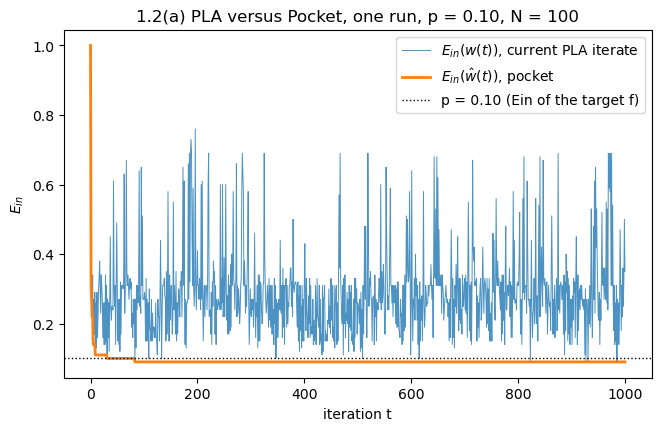

In [3]:
T, N12, NTEST = 1000, 100, 10_000
P_LIST = [0.0, 0.05, 0.10, 0.20, 0.30]

# (a) one run with p = 0.10
rng12a = mc.rng_for("1_2a")
w_t = mc.random_linear_target(rng12a)
X, _, y = mc.linear_target_data(rng12a, N12, w_t, flip=0.10)
w_hat, ein_w, ein_hat = mc.pocket(X, y, rng12a, T=T)
print(f"(a) p = 0.10: final Ein(w(T)) = {ein_w[-1]:.2f}, Ein(w_hat) = {ein_hat[-1]:.2f} "
      f"(10 labels flipped, so Ein = 0.10 is what the target itself scores)")

fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
ax.plot(ein_w, lw=0.7, alpha=0.8, label=r"$E_{in}(w(t))$, current PLA iterate")
ax.plot(ein_hat, lw=2, label=r"$E_{in}(\hat w(t))$, pocket")
ax.axhline(0.10, color="k", ls=":", lw=1, label="p = 0.10 (Ein of the target f)")
ax.set(xlabel="iteration t", ylabel=r"$E_{in}$", title="1.2(a) PLA versus Pocket, one run, p = 0.10, N = 100")
ax.legend()
mc.savefig(fig, "1_2a_ein_curves")
plt.show()

**Interpretation.** With 10% of the labels flipped, PLA never stops and its iterate ends at $E_{in}=0.35$. Pocket keeps the best iterate, so its error only falls, ending at 0.09, just below the 0.10 of the target itself because it fits a few flipped labels.

500 Pocket runs in 1.5 s
    p        Ein(w_hat)     Eout vs clean f     Eout vs flipped  median clean
 0.00     0.0002 ± 0.0001     0.0138 ± 0.0010     0.0138 ± 0.0010        0.0113
 0.05     0.0584 ± 0.0014     0.0288 ± 0.0021     0.0760 ± 0.0019        0.0234
 0.10     0.1078 ± 0.0017     0.0337 ± 0.0028     0.1269 ± 0.0022        0.0271
 0.20     0.2051 ± 0.0020     0.0532 ± 0.0034     0.2318 ± 0.0021        0.0456
 0.30     0.2917 ± 0.0018     0.0907 ± 0.0066     0.3361 ± 0.0026        0.0873


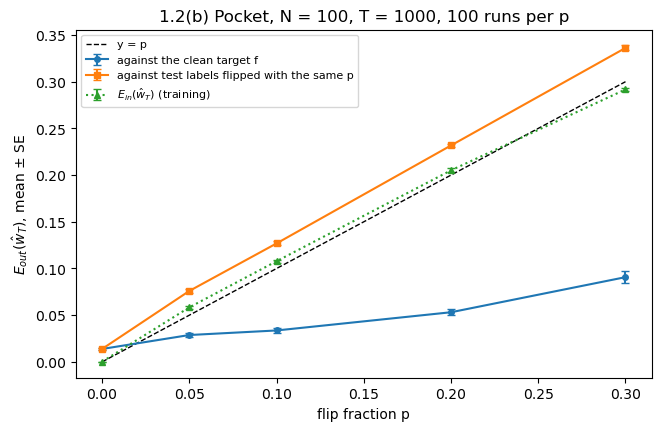

In [4]:
# (b) Eout vs clean and flipped test labels
RUNS12 = 100
rng12b = mc.rng_for("1_2b")
eout_clean = np.zeros((len(P_LIST), RUNS12))
eout_flip = np.zeros((len(P_LIST), RUNS12))
ein_final = np.zeros((len(P_LIST), RUNS12))
t0 = time.perf_counter()
for i, p in enumerate(P_LIST):
    for r in range(RUNS12):
        w_t = mc.random_linear_target(rng12b)
        X, _, y = mc.linear_target_data(rng12b, N12, w_t, flip=p)
        Xte, yte_clean, yte_flip = mc.linear_target_data(rng12b, NTEST, w_t, flip=p)
        w_hat, _, eh = mc.pocket(X, y, rng12b, T=T)
        ein_final[i, r] = eh[-1]
        eout_clean[i, r] = mc.ein_01(w_hat, Xte, yte_clean)
        eout_flip[i, r] = mc.ein_01(w_hat, Xte, yte_flip)
print(f"{len(P_LIST) * RUNS12} Pocket runs in {time.perf_counter() - t0:.1f} s")
print(f"{'p':>5}{'Ein(w_hat)':>18}{'Eout vs clean f':>20}{'Eout vs flipped':>20}{'median clean':>14}")
for i, p in enumerate(P_LIST):
    print(f"{p:>5.2f}" + "".join("{:>11.4f} ± {:.4f}".format(*mc.mean_se(a[i])) for a in (ein_final, eout_clean, eout_flip))
          + f"{np.median(eout_clean[i]):>14.4f}")

fig, ax = plt.subplots(figsize=(6.5, 4.2), constrained_layout=True)
for a, lab, mk in ((eout_clean, "against the clean target f", "o-"), (eout_flip, "against test labels flipped with the same p", "s-"),
                   (ein_final, r"$E_{in}(\hat w_T)$ (training)", "^:")):
    m, se = mc.mean_se(a, axis=1)
    ax.errorbar(P_LIST, m, yerr=se, fmt=mk, ms=4, capsize=3, label=lab)
ax.plot([0, 0.3], [0, 0.3], "k--", lw=1, label="y = p")
ax.set(xlabel="flip fraction p", ylabel=r"$E_{out}(\hat w_T)$, mean ± SE", title=f"1.2(b) Pocket, N = 100, T = 1000, {RUNS12} runs per p")
ax.legend(fontsize=8)
mc.savefig(fig, "1_2b_eout_vs_p")
plt.show()

**Interpretation.** Against the clean target, $E_{out}(\hat w_T)$ stays small ($0.034\pm0.003$ at $p=0.10$, $0.091\pm0.007$ at $p=0.30$), because symmetric flips barely move the best line. Against flipped test labels it is $0.127\pm0.002$ and $0.336\pm0.003$ and cannot drop below $p$. A flipped point is wrong exactly where $\hat w$ agrees with $f$, so $E_{out}^{flip}=p+(1-2p)E_{out}^{clean}$, which the numbers satisfy ($0.10+0.8\times0.034=0.127$).

**1.2(c) PLA convergence bound.** PLA from $w=0$ makes at most $R^2\lVert w^*\rVert^2/\rho^2$ updates, with $\rho=\min_n y_nw^{*T}x_n$ and $R=\max_n\lVert x_n\rVert$. We use $w^*$ = the target's weights (DECISIONS row 20).

In [5]:
RUNS12c = 500
rng12c = mc.rng_for("1_2c")
for Nc in (100, 1000):
    updates, bound = np.zeros(RUNS12c), np.zeros(RUNS12c)
    for r in range(RUNS12c):
        w_t = mc.random_linear_target(rng12c)
        X, y, _ = mc.linear_target_data(rng12c, Nc, w_t)
        n_up = mc.pla(X, y, rng12c, T=T)[2]
        updates[r] = np.nan if n_up is None else n_up
        bound[r] = np.max(np.sum(X**2, axis=1)) * (w_t @ w_t) / np.min(y * (X @ w_t)) ** 2
    fail = np.isnan(updates).astype(float)
    print(f"N = {Nc:4d}: not converged within T in " + "{:.3f} ± {:.3f}".format(*mc.mean_se(fail))
          + f" of runs | median updates {np.nanmedian(updates):.0f} | median bound {np.median(bound):.3g}")

N =  100: not converged within T in 0.004 ± 0.003 of runs | median updates 58 | median bound 7.3e+04


N = 1000: not converged within T in 0.214 ± 0.018 of runs | median updates 421 | median bound 6.81e+06


**Interpretation.** PLA fails to converge within $T=1000$ in $0.4\%\pm0.3\%$ of runs at $N=100$ and $21.4\%\pm1.8\%$ at $N=1000$, and the median number of updates grows from 58 to 421. More points sit closer to the boundary, so the margin $\rho$ shrinks and the bound $R^2\lVert w^*\rVert^2/\rho^2$ grows (median $7.3\times10^4$ to $6.8\times10^6$). The bound is a worst case over all update orders, so it explains the trend but not the counts.

## 1.3 ⋆ Initialization matters

Pocket from $w_0=0$ against $w_0=w_{lin}$ (least squares on the noisy labels). $N=100$, $p=0.10$, $T=1000$, 100 runs per $d\in\{2,10\}$; both starts see the same data. The $d=10$ target is redrawn until each class has $\ge30\%$ of the points (DECISIONS row 1a); "within 1%" means $E_{in}(\hat w(t))\le E_{in}(\hat w_T)+0.01$ (row 1b).

d =  2, w0 = 0    : Ein(0) 1.0000, final Ein 0.1072 ± 0.0015, iterations to final + 0.01: 137.1 ± 17.9 (median 66)
d =  2, w0 = w_lin: Ein(0) 0.1352, final Ein 0.1035 ± 0.0009, iterations to final + 0.01: 119.4 ± 17.6 (median 42)
d = 10, w0 = 0    : Ein(0) 1.0000, final Ein 0.1131 ± 0.0020, iterations to final + 0.01: 277.8 ± 22.7 (median 227)
d = 10, w0 = w_lin: Ein(0) 0.1378, final Ein 0.1137 ± 0.0020, iterations to final + 0.01: 216.0 ± 24.5 (median 137)


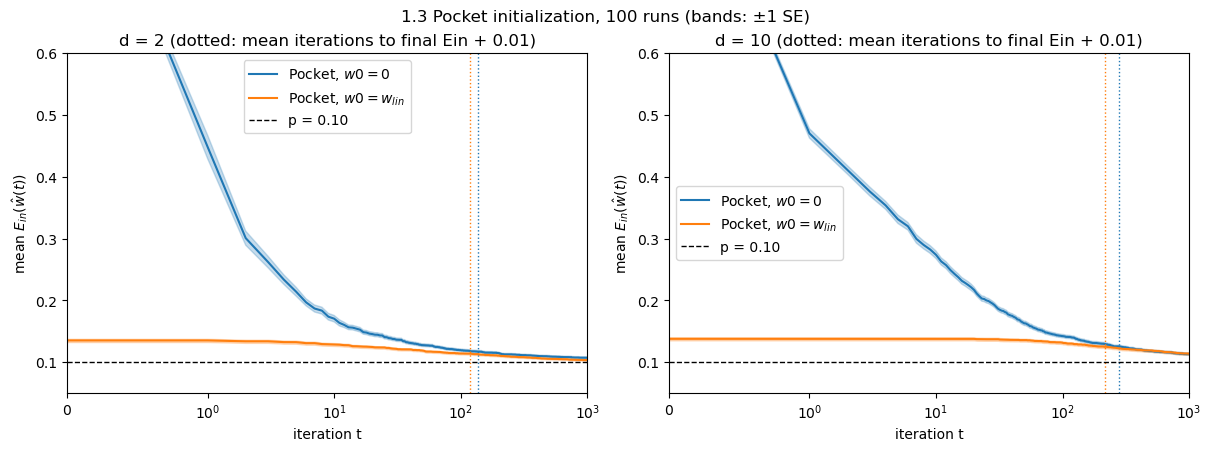

In [6]:
T13, N13, P13, RUNS13 = 1000, 100, 0.10, 100
res13 = {}
for d in (2, 10):
    rng_data, rng_pk = mc.rng_for(f"1_3_d{d}"), mc.rng_for(f"1_3_d{d}_pocket")
    curves = {"w0 = 0": np.zeros((RUNS13, T13 + 1)), "w0 = w_lin": np.zeros((RUNS13, T13 + 1))}
    for r in range(RUNS13):
        while True:
            w_t = mc.random_linear_target(rng_data, d)
            X, y_clean, y = mc.linear_target_data(rng_data, N13, w_t, flip=P13)
            if d == 2 or min(np.mean(y_clean == 1), np.mean(y_clean == -1)) >= 0.3:
                break
        w_lin = mc.solve_lstsq(X, y)
        for name, w0 in (("w0 = 0", None), ("w0 = w_lin", w_lin)):
            curves[name][r] = mc.pocket(X, y, rng_pk, T=T13, w0=w0)[2]
    res13[d] = curves


def iters_to_final(eh, tol=0.01):
    return np.argmax(eh <= eh[:, -1:] + tol, axis=1)


for d, curves in res13.items():
    for name, eh in curves.items():
        it = iters_to_final(eh)
        print(f"d = {d:2d}, {name:<10}: Ein(0) " + "{:.4f}".format(eh[:, 0].mean()) + ", final Ein " + "{:.4f} ± {:.4f}".format(*mc.mean_se(eh[:, -1]))
              + ", iterations to final + 0.01: " + "{:.1f} ± {:.1f}".format(*mc.mean_se(it)) + f" (median {np.median(it):.0f})")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), constrained_layout=True)
for ax, (d, curves) in zip(axes, res13.items()):
    for (name, eh), col in zip(curves.items(), ("C0", "C1")):
        m, se = mc.mean_se(eh)
        t = np.arange(T13 + 1)
        ax.plot(t, m, color=col, label=rf"Pocket, ${name.replace('w_lin', 'w_{lin}')}$")
        ax.fill_between(t, m - se, m + se, color=col, alpha=0.25)
        ax.axvline(np.mean(iters_to_final(eh)), color=col, ls=":", lw=1)
    ax.axhline(P13, color="k", ls="--", lw=1, label="p = 0.10")
    ax.set_xscale("symlog", linthresh=1)
    ax.set(xlim=(0, T13), xlabel="iteration t", ylabel=r"mean $E_{in}(\hat w(t))$", ylim=(0.05, 0.6),
           title=f"d = {d} (dotted: mean iterations to final Ein + 0.01)")
    ax.legend()
fig.suptitle(f"1.3 Pocket initialization, {RUNS13} runs (bands: ±1 SE)")
mc.savefig(fig, "1_3_init")
plt.show()

**Interpretation.** Starting at $w_{lin}$ puts Pocket at $E_{in}\approx0.14$ instead of 1, so it needs fewer iterations to get within 0.01 of its final error: $119\pm18$ against $137\pm18$ for $d=2$, and $216\pm25$ against $278\pm23$ for $d=10$. The saving grows with $d$ (18 against 62 iterations), because PLA from 0 builds its direction one point at a time while $w_{lin}$ costs one least-squares solve in any dimension. The final errors are almost equal (0.1035 and 0.1072 for $d=2$, 0.1137 and 0.1131 for $d=10$), since the first PLA updates move away from $w_{lin}$ and only the pocket keeps the head start.

## 1.4 Real data: handwritten 1s and 5s

`load_digits`, digits 1 ($y=+1$) and 5. Features from `mc.intensity_symmetry` (pixels / 16), scaled to $[-1,1]$ on the training split of a stratified 70/30 split (tag `1_4_split`). Pocket ($T=1000$) is run 100 times; plots show the median-$E_{in}$ run.

364 images (182 ones, 182 fives); train 254 (127 ones), test 110 (55 ones)
digit 1 (training, unscaled): intensity 0.302 ± sd 0.043, symmetry -0.216 ± sd 0.103
digit 5 (training, unscaled): intensity 0.300 ± sd 0.029, symmetry -0.252 ± sd 0.047


linear (3 dims incl. bias)                 Ein 0.3567 ± 0.0008   Etest 0.3522 ± 0.0015   (median-Ein run: Ein 0.3622, Etest 0.3545)


3rd-order polynomial (10 dims incl. bias)  Ein 0.2221 ± 0.0004   Etest 0.2065 ± 0.0011   (median-Ein run: Ein 0.2244, Etest 0.2273)


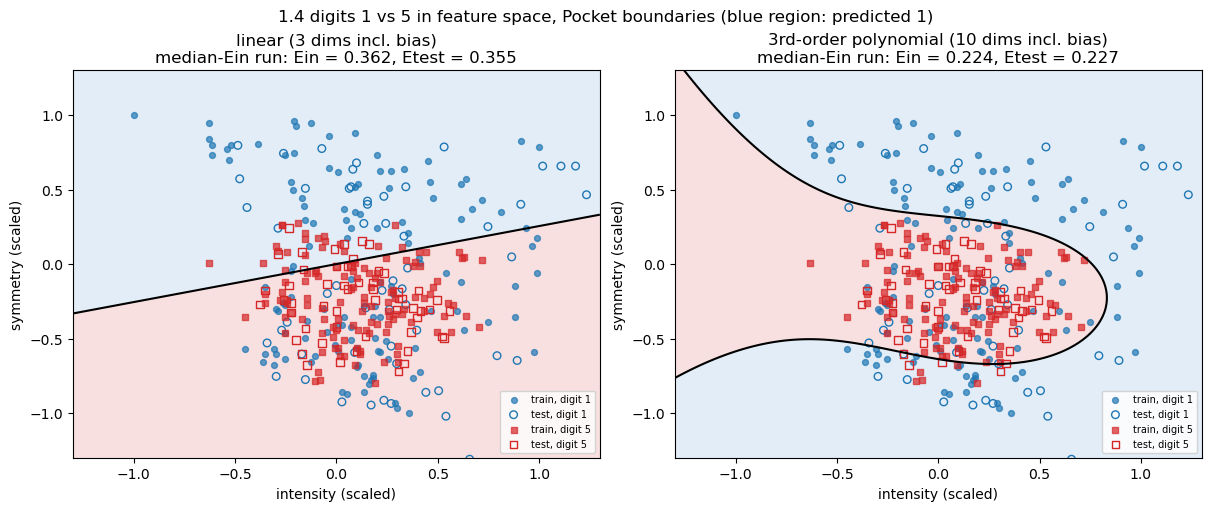

In [7]:
from sklearn.datasets import load_digits   # data loading only (R1)

dig = load_digits()
keep = np.isin(dig.target, [1, 5])
F_all = mc.intensity_symmetry(dig.images[keep] / 16.0)
y_all = np.where(dig.target[keep] == 1, 1.0, -1.0)
tr14, te14 = mc.stratified_split(y_all, 0.3, mc.rng_for("1_4_split"))
F_tr, prm14 = mc.minmax_scale(F_all[tr14])
F_te = mc.apply_minmax(F_all[te14], prm14)
y_tr, y_te = y_all[tr14], y_all[te14]
print(f"{keep.sum()} images ({np.sum(y_all == 1)} ones, {np.sum(y_all == -1)} fives); "
      f"train {tr14.size} ({np.sum(y_tr == 1)} ones), test {te14.size} ({np.sum(y_te == 1)} ones)")
for lab, digit in ((1, 1), (-1, 5)):
    Fc = F_all[tr14][y_tr == lab]
    print(f"digit {digit} (training, unscaled): intensity {Fc[:, 0].mean():.3f} ± sd {Fc[:, 0].std():.3f}, "
          f"symmetry {Fc[:, 1].mean():.3f} ± sd {Fc[:, 1].std():.3f}")

PHI = {"linear (3 dims incl. bias)": lambda F: mc.add_bias(F),
       "3rd-order polynomial (10 dims incl. bias)": lambda F: mc.add_bias(mc.poly_features(F, 3))}
RUNS14 = 100
res14 = {}
for name, phi in PHI.items():
    Z_tr, Z_te = phi(F_tr), phi(F_te)
    rng14 = mc.rng_for(f"1_4_{name[:6]}")
    W, ein, etest = [], np.zeros(RUNS14), np.zeros(RUNS14)
    for r in range(RUNS14):
        w_hat, _, eh = mc.pocket(Z_tr, y_tr, rng14, T=1000)
        W.append(w_hat)
        ein[r], etest[r] = eh[-1], mc.ein_01(w_hat, Z_te, y_te)
    rep = int(np.argsort(ein, kind="stable")[RUNS14 // 2])  # median-Ein run
    res14[name] = dict(W=np.array(W), ein=ein, etest=etest, rep=rep, phi=phi)
    print(f"{name:<42} Ein " + "{:.4f} ± {:.4f}".format(*mc.mean_se(ein)) + "   Etest " + "{:.4f} ± {:.4f}".format(*mc.mean_se(etest))
          + f"   (median-Ein run: Ein {ein[rep]:.4f}, Etest {etest[rep]:.4f})")

g1, g2 = np.meshgrid(np.linspace(-1.3, 1.3, 400), np.linspace(-1.3, 1.3, 400))
G = np.column_stack([g1.ravel(), g2.ravel()])
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, (name, r) in zip(axes, res14.items()):
    s = (r["phi"](G) @ r["W"][r["rep"]]).reshape(g1.shape)
    ax.contourf(g1, g2, s > 0, levels=[-0.5, 0.5, 1.5], colors=["#f4cccc", "#cfe2f3"], alpha=0.6)
    ax.contour(g1, g2, s, levels=[0], colors="k", linewidths=1.5)
    for lab, mk, c in ((1, "o", "C0"), (-1, "s", "C3")):
        ax.scatter(*F_tr[y_tr == lab].T, marker=mk, s=18, c=c, alpha=0.7, label=f"train, digit {1 if lab == 1 else 5}")
        ax.scatter(*F_te[y_te == lab].T, marker=mk, s=30, facecolors="none", edgecolors=c, label=f"test, digit {1 if lab == 1 else 5}")
    ax.set(xlim=(-1.3, 1.3), ylim=(-1.3, 1.3), xlabel="intensity (scaled)", ylabel="symmetry (scaled)",
           title=f"{name}\nmedian-Ein run: Ein = {r['ein'][r['rep']]:.3f}, Etest = {r['etest'][r['rep']]:.3f}")
    ax.legend(fontsize=7, loc="lower right")
fig.suptitle("1.4 digits 1 vs 5 in feature space, Pocket boundaries (blue region: predicted 1)")
mc.savefig(fig, "1_4_boundaries")
plt.show()

**Interpretation.** The two features barely separate the classes in `load_digits`. Mean intensity is 0.302 for 1s and 0.300 for 5s, and the 5s form a tight cluster in symmetry with 1s on both sides. No line separates that (linear Pocket: $E_{in}=0.357\pm0.001$, $E_{test}=0.352\pm0.002$), while the cubic boundary closes around the 5s ($E_{in}=0.222\pm0.0004$, $E_{test}=0.2065\pm0.0011$).

In [8]:
# (c) 95% Hoeffding bound (M = 1)
eps14 = mc.hoeffding_eps(te14.size, 0.05)
print(f"n = {te14.size}: eps = {eps14:.3f} (M = 1), {mc.hoeffding_eps(te14.size, 0.05, M=2):.3f} (M = 2)")
for name, r in res14.items():
    e = r["etest"][r["rep"]]
    print(f"{name:<42} Etest = {e:.3f}  ->  Eout <= {e + eps14:.3f}")
for name, dvc in (("linear", 3), ("cubic", 10)):  # VC bound with m_H(2N) <= (2N)^dvc + 1
    print(f"VC term, {name} (d_vc = {dvc}): {np.sqrt(8 / tr14.size * np.log(4 * ((2 * tr14.size) ** dvc + 1) / 0.05)):.2f}")

n = 110: eps = 0.129 (M = 1), 0.141 (M = 2)
linear (3 dims incl. bias)                 Etest = 0.355  ->  Eout <= 0.484
3rd-order polynomial (10 dims incl. bias)  Etest = 0.227  ->  Eout <= 0.357
VC term, linear (d_vc = 3): 0.85
VC term, cubic (d_vc = 10): 1.45


**Interpretation.** With 110 test points the 95% Hoeffding margin is 0.129, so $E_{out}\le0.484$ for the linear model and $\le0.357$ for the cubic one (0.141 if the test set picks between them, $M=2$). The VC argument favours the linear model ($d_{vc}=3$ against 10 on 254 points), but the test bound, valid because the test set trained and selected nothing, favours the cubic model, whose $E_{test}$ shows no gap to $E_{in}$. We trust the cubic model; Pocket itself only guarantees a low $E_{in}$, so any claim about $E_{out}$ needs a bound like this.